Install libraries

In [2]:
!pip install -q pandas numpy scipy scikit-learn matplotlib seaborn streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 58.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 68.3 MB/s eta 0:00:00


Upload datasets

In [3]:
from google.colab import files

uploaded = files.upload()

required_files = ["Books.csv", "Ratings.csv", "Users.csv"]

missing_files = [f for f in required_files if f not in uploaded]

if missing_files:
    raise FileNotFoundError(
        f"Please upload these files: {missing_files}"
    )

print("All three datasets uploaded successfully!")

Saving Books.csv to Books.csv
Saving Ratings.csv to Ratings.csv
Saving Users.csv to Users.csv
All three datasets uploaded successfully!


Load datasets and preprocess

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import os
import subprocess
import time

from scipy.sparse import csr_matrix
from sklearn.model_selection import train_test_split
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import mean_absolute_error, mean_squared_error

Books = pd.read_csv(
    "Books.csv", sep=";", encoding="latin-1",
    on_bad_lines="skip", dtype={"ISBN": str}
)

Ratings = pd.read_csv(
    "Ratings.csv", sep=";", encoding="latin-1",
    on_bad_lines="skip", dtype={"ISBN": str}
)

Users = pd.read_csv(
    "Users.csv", sep=";", encoding="latin-1",
    on_bad_lines="skip"
)

Books.columns = Books.columns.str.strip()
Ratings.columns = Ratings.columns.str.strip()

print("Books dataset:", Books.shape)
print("Ratings dataset:", Ratings.shape)
print("Users dataset:", Users.shape)

display(Books.head())
display(Ratings.head())
display(Users.head())

print("\nMissing values in Books:")
display(Books.isnull().sum())

print("\nMissing values in Ratings:")
display(Ratings.isnull().sum())

print("\nMissing values in Users:")
display(Users.isnull().sum())

Books dataset: (249936, 1)
Ratings dataset: (1149780, 1)
Users dataset: (278698, 1)


,"ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L"
0,"0195153448,Classical Mythology,Mark P. O. Morf..."
1,"0002005018,Clara Callan,Richard Bruce Wright,2..."
2,"0060973129,Decision in Normandy,Carlo D'Este,1..."
3,"0374157065,Flu: The Story of the Great Influen..."
4,"0399135782,The Kitchen God's Wife,Amy Tan,1991..."


,"User-ID,ISBN,Book-Rating"
0,"276725,034545104X,0"
1,"276726,0155061224,5"
2,"276727,0446520802,0"
3,"276729,052165615X,3"
4,"276729,0521795028,6"


,"User-ID,Location,Age"
0,"1,""nyc, new york, usa"","
1,"2,""stockton, california, usa"",18.0"
2,"3,""moscow, yukon territory, russia"","
3,"4,""porto, v.n.gaia, portugal"",17.0"
4,"5,""farnborough, hants, united kingdom"","



Missing values in Books:


,0
"ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L",0



Missing values in Ratings:


,0
"User-ID,ISBN,Book-Rating",0



Missing values in Users:


,0
"User-ID,Location,Age",0


Exploratory Data Analysis (EDA)

/tmp/ipykernel_931/2932774557.py:7: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  Books = pd.read_csv(


Total ratings: 1149780
Explicit ratings: 433671
Unique users: 105283
Unique books: 340553
Average explicit rating: 7.6


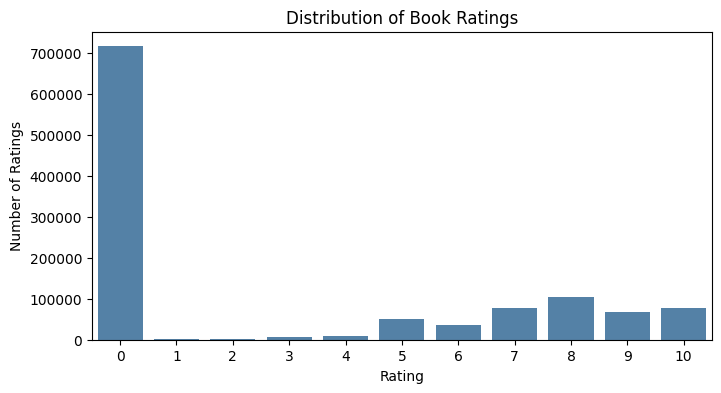

,ISBN,Number of Ratings,Book-Title
0,0316666343,707,The Lovely Bones: A Novel
1,0971880107,581,Wild Animus
2,0385504209,487,The Da Vinci Code
3,0312195516,383,The Red Tent (Bestselling Backlist)
4,0679781587,333,NaN
5,0060928336,320,Divine Secrets of the Ya-Ya Sisterhood: A Novel
6,059035342X,313,Harry Potter and the Sorcerer's Stone (Harry P...
7,0142001740,307,The Secret Life of Bees
8,0446672211,295,Where the Heart Is (Oprah's Book Club (Paperba...
9,044023722X,281,A Painted House


In [6]:
# Re-read the datasets using comma as the separator
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Safely load the datasets with comma separator
Books = pd.read_csv(
    "Books.csv", sep=",", encoding="latin-1",
    on_bad_lines="skip", dtype={"ISBN": str}
)

Ratings = pd.read_csv(
    "Ratings.csv", sep=",", encoding="latin-1",
    on_bad_lines="skip", dtype={"ISBN": str}
)

# Strip whitespaces from column names
Books.columns = Books.columns.str.strip()
Ratings.columns = Ratings.columns.str.strip()

# Keep only valid, explicitly given ratings (1–10)
Ratings["User-ID"] = pd.to_numeric(
    Ratings["User-ID"], errors="coerce"
)
Ratings["Book-Rating"] = pd.to_numeric(
    Ratings["Book-Rating"], errors="coerce"
)
Ratings["ISBN"] = Ratings["ISBN"].astype("string").str.strip()

ratings_clean = Ratings.dropna(
    subset=["User-ID", "ISBN", "Book-Rating"]
).copy()

ratings_clean = ratings_clean[
    (ratings_clean["Book-Rating"] >= 0) &
    (ratings_clean["Book-Rating"] <= 10)
].copy()

ratings_clean["User-ID"] = ratings_clean["User-ID"].astype(int)

ratings_explicit = ratings_clean[
    ratings_clean["Book-Rating"] > 0
].copy()

print("Total ratings:", len(ratings_clean))
print("Explicit ratings:", len(ratings_explicit))
print("Unique users:", ratings_clean["User-ID"].nunique())
print("Unique books:", ratings_clean["ISBN"].nunique())
if len(ratings_explicit) > 0:
    print("Average explicit rating:", round(
        ratings_explicit["Book-Rating"].mean(), 2
    ))

plt.figure(figsize=(8, 4))
sns.countplot(
    data=ratings_clean,
    x="Book-Rating",
    color="steelblue"
)
plt.title("Distribution of Book Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.show()

top_books = (
    ratings_explicit.groupby("ISBN")
    .size()
    .sort_values(ascending=False)
    .head(10)
    .reset_index(name="Number of Ratings")
    .merge(Books[["ISBN", "Book-Title"]].drop_duplicates("ISBN"),
           on="ISBN", how="left")
)

display(top_books)

Prepare the machine-learning data

In [7]:
ml_data = ratings_explicit[
    ["User-ID", "ISBN", "Book-Rating"]
].copy()

ml_data = ml_data.drop_duplicates(
    subset=["User-ID", "ISBN"], keep="last"
)

# Keep users with at least 5 ratings
user_counts = ml_data.groupby("User-ID").size()
active_users = user_counts[user_counts >= 5].index

ml_data = ml_data[
    ml_data["User-ID"].isin(active_users)
].copy()

# Keep books with at least 5 ratings
book_counts = ml_data.groupby("ISBN").size()
popular_books = book_counts[book_counts >= 5].index

ml_data = ml_data[
    ml_data["ISBN"].isin(popular_books)
].copy()

if ml_data.empty:
    raise ValueError(
        "No data remains after filtering. Check the uploaded datasets."
    )

user_book_matrix = ml_data.pivot_table(
    index="User-ID",
    columns="ISBN",
    values="Book-Rating"
)

total_cells = user_book_matrix.shape[0] * user_book_matrix.shape[1]
sparsity = (
    1 - user_book_matrix.count().sum() / total_cells
) * 100

print("Filtered ratings:", len(ml_data))
print("User-book matrix shape:", user_book_matrix.shape)
print("Matrix sparsity:", round(sparsity, 2), "%")

display(ml_data.head())

Filtered ratings: 141081
User-book matrix shape: (13030, 11234)
Matrix sparsity: 99.9 %


,User-ID,ISBN,Book-Rating
16,276747,0060517794,9
19,276747,0671537458,9
20,276747,0679776818,8
133,276822,0060096195,10
137,276822,0375821813,9


Train the SVD model

In [8]:
train_data, test_data = train_test_split(
    ml_data,
    test_size=0.20,
    random_state=42
)

user_ids = train_data["User-ID"].unique()
book_ids = train_data["ISBN"].unique()

user_to_index = {
    user_id: i for i, user_id in enumerate(user_ids)
}

book_to_index = {
    isbn: i for i, isbn in enumerate(book_ids)
}

rows = train_data["User-ID"].map(user_to_index).to_numpy()
cols = train_data["ISBN"].map(book_to_index).to_numpy()
values = train_data["Book-Rating"].to_numpy(dtype=float)

rating_matrix = csr_matrix(
    (values, (rows, cols)),
    shape=(len(user_ids), len(book_ids))
)

n_components = min(
    20, rating_matrix.shape[0] - 1,
    rating_matrix.shape[1] - 1
)

if n_components < 1:
    raise ValueError("Not enough users/books to train the SVD model.")

svd_model = TruncatedSVD(
    n_components=n_components,
    random_state=42
)

user_features = svd_model.fit_transform(rating_matrix)
book_features = svd_model.components_

predicted_matrix = np.clip(
    user_features @ book_features, 1, 10
)

print("SVD training completed!")
print("Training matrix:", rating_matrix.shape)
print("Predicted matrix:", predicted_matrix.shape)
print("SVD components:", n_components)

SVD training completed!
Training matrix: (12712, 11234)
Predicted matrix: (12712, 11234)
SVD components: 20


Evaluate rating prediction

In [9]:
actual_ratings = []
predicted_ratings = []

for _, row in test_data.iterrows():
    uid = int(row["User-ID"])
    isbn = row["ISBN"]

    if uid in user_to_index and isbn in book_to_index:
        actual_ratings.append(float(row["Book-Rating"]))
        predicted_ratings.append(
            float(predicted_matrix[
                user_to_index[uid],
                book_to_index[isbn]
            ])
        )

if not actual_ratings:
    raise ValueError(
        "No matching test records. Check the dataset and split."
    )

mae = mean_absolute_error(
    actual_ratings, predicted_ratings
)

rmse = np.sqrt(
    mean_squared_error(actual_ratings, predicted_ratings)
)

print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))

MAE: 6.7575
RMSE: 6.9875


Create Top-N recommendations

In [10]:
def recommend_books(user_id, n=10):
    if user_id not in user_to_index:
        return pd.DataFrame()

    user_index = user_to_index[user_id]

    recommendations = pd.DataFrame({
        "ISBN": book_ids,
        "Predicted Rating": predicted_matrix[user_index]
    })

    already_rated = set(
        train_data.loc[
            train_data["User-ID"] == user_id, "ISBN"
        ]
    )

    recommendations = recommendations[
        ~recommendations["ISBN"].isin(already_rated)
    ]

    recommendations = recommendations.nlargest(
        n, "Predicted Rating"
    )

    book_info = Books[
        ["ISBN", "Book-Title", "Book-Author"]
    ].drop_duplicates("ISBN").copy()

    book_info = book_info.fillna("Unknown")

    recommendations = recommendations.merge(
        book_info, on="ISBN", how="left"
    )

    recommendations["Book-Title"] = (
        recommendations["Book-Title"].fillna("Unknown")
    )
    recommendations["Book-Author"] = (
        recommendations["Book-Author"].fillna("Unknown")
    )
    recommendations["Predicted Rating"] = (
        recommendations["Predicted Rating"].round(2)
    )

    return recommendations[
        ["ISBN", "Book-Title", "Book-Author", "Predicted Rating"]
    ]

example_user_id = int(train_data["User-ID"].iloc[0])

print("Example User ID:", example_user_id)
display(recommend_books(example_user_id, 10))

Example User ID: 206202


,ISBN,Book-Title,Book-Author,Predicted Rating
0,006029471X,Haunted : A Tale of the Mediator,Meg Cabot,1.0
1,0770422632,Unknown,Unknown,1.0
2,0312263120,Digital Fortress : A Thriller,Dan Brown,1.0
3,0451203054,Praying for Sleep,Jeffrey Deaver,1.0
4,0380977737,Resort To Murder: A Henrie O Mystery,Carolyn G. Hart,1.0
5,0440110653,"CRY IN THE NIGHT, A",MARY HIGGINS CLARK,1.0
6,055357227X,"The Web (Alex Delaware Series, No. 10)",JONATHAN KELLERMAN,1.0
7,0553110845,"House Corrino (Dune: House Trilogy, Book 3)",Brian Herbert,1.0
8,0345348656,Lord Foul's Bane (The Chronicles of Thomas Cov...,Stephen R. Donaldson,1.0
9,0749391251,Unknown,Unknown,1.0


Calculate Precision@10 and Recall@10

In [11]:
K = 10
relevant_threshold = 7

precisions = []
recalls = []

for uid in test_data["User-ID"].unique()[:200]:
    if uid not in user_to_index:
        continue

    user_index = user_to_index[uid]

    candidates = pd.DataFrame({
        "ISBN": book_ids,
        "Predicted Rating": predicted_matrix[user_index]
    })

    already_rated = set(
        train_data.loc[train_data["User-ID"] == uid, "ISBN"]
    )

    candidates = candidates[
        ~candidates["ISBN"].isin(already_rated)
    ]

    top_k = candidates.nlargest(K, "Predicted Rating")
    recommended = set(top_k["ISBN"])

    relevant = set(
        test_data.loc[
            (test_data["User-ID"] == uid) &
            (test_data["Book-Rating"] >= relevant_threshold),
            "ISBN"
        ]
    ) & set(book_ids)

    if not relevant:
        continue

    hits = len(recommended & relevant)

    precisions.append(
        hits / len(recommended) if recommended else 0
    )
    recalls.append(hits / len(relevant))

average_precision = float(np.mean(precisions)) if precisions else 0.0
average_recall = float(np.mean(recalls)) if recalls else 0.0

print("Precision@10:", round(average_precision, 4))
print("Recall@10:", round(average_recall, 4))

Precision@10: 0.0172
Recall@10: 0.0153


Display final results

,Evaluation Metric,Score
0,MAE,6.7575
1,RMSE,6.9875
2,Precision@10,0.0172
3,Recall@10,0.0153


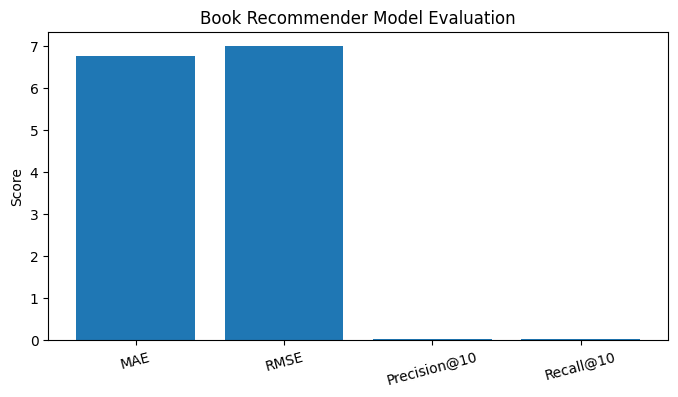

In [12]:
final_results = pd.DataFrame({
    "Evaluation Metric": [
        "MAE",
        "RMSE",
        "Precision@10",
        "Recall@10"
    ],
    "Score": [
        mae,
        rmse,
        average_precision,
        average_recall
    ]
})

display(final_results.round(4))

plt.figure(figsize=(8, 4))
plt.bar(
    final_results["Evaluation Metric"],
    final_results["Score"]
)
plt.title("Book Recommender Model Evaluation")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.show()

final_results.to_csv("final_results.csv", index=False)

 Create the complete Streamlit app

In [13]:
import pickle
import pandas as pd

book_info = Books[
    ["ISBN", "Book-Title", "Book-Author"]
].drop_duplicates("ISBN").copy()

book_info = book_info.fillna("Unknown")
book_info["ISBN"] = book_info["ISBN"].astype(str)

train_data = train_data.copy()
train_data["ISBN"] = train_data["ISBN"].astype(str)

with open("svd_model.pkl", "wb") as f:
    pickle.dump(svd_model, f)

with open("predicted_matrix.pkl", "wb") as f:
    pickle.dump(predicted_matrix, f)

with open("user_to_index.pkl", "wb") as f:
    pickle.dump(user_to_index, f)

with open("book_ids.pkl", "wb") as f:
    pickle.dump(np.asarray(book_ids, dtype=str), f)

with open("train_data.pkl", "wb") as f:
    pickle.dump(train_data, f)

with open("metrics.pkl", "wb") as f:
    pickle.dump({
        "MAE": float(mae),
        "RMSE": float(rmse),
        "Precision@10": float(average_precision),
        "Recall@10": float(average_recall)
    }, f)

book_info.to_csv("book_info.csv", index=False)

print("All model files saved successfully!")

import os
print("\nSaved files:")
for filename in [
    "svd_model.pkl",
    "predicted_matrix.pkl",
    "user_to_index.pkl",
    "book_ids.pkl",
    "train_data.pkl",
    "metrics.pkl",
    "book_info.csv",
    "final_results.csv"
]:
    print(filename, "—", os.path.getsize(filename), "bytes")

All model files saved successfully!

Saved files:
svd_model.pkl — 1798506 bytes
predicted_matrix.pkl — 1142453028 bytes
user_to_index.pkl — 279570 bytes
book_ids.pkl — 584324 bytes
train_data.pkl — 3602117 bytes
metrics.pkl — 92 bytes
book_info.csv — 17749459 bytes
final_results.csv — 134 bytes


Create the complete Streamlit app


In [14]:
%%writefile app.py
import pickle
import pandas as pd
import streamlit as st

st.set_page_config(
    page_title="Book Recommender",
    page_icon="📚",
    layout="wide"
)

@st.cache_resource
def load_data():
    with open("svd_model.pkl", "rb") as f:
        model = pickle.load(f)

    with open("predicted_matrix.pkl", "rb") as f:
        predictions = pickle.load(f)

    with open("user_to_index.pkl", "rb") as f:
        user_map = pickle.load(f)

    with open("book_ids.pkl", "rb") as f:
        book_ids = pickle.load(f)

    with open("train_data.pkl", "rb") as f:
        train_data = pickle.load(f)

    with open("metrics.pkl", "rb") as f:
        metrics = pickle.load(f)

    book_info = pd.read_csv(
        "book_info.csv", dtype={"ISBN": str}
    ).fillna("Unknown")

    return (
        model, predictions, user_map,
        book_ids, train_data, metrics, book_info
    )

try:
    (
        model, predictions, user_map,
        book_ids, train_data, metrics, book_info
    ) = load_data()

except Exception as error:
    st.error("Unable to load trained model files.")
    st.exception(error)
    st.stop()

st.title("📚 Book Recommender with Rating Prediction")
st.write(
    "Discover personalized books using an SVD-based "
    "machine-learning model."
)

st.sidebar.header("Recommendation Settings")
user_input = st.sidebar.text_input("Enter User ID")

number = st.sidebar.slider(
    "Number of recommendations", 1, 20, 10
)

st.header("📊 Model Performance")
c1, c2, c3, c4 = st.columns(4)

c1.metric("MAE", f"{metrics['MAE']:.3f}")
c2.metric("RMSE", f"{metrics['RMSE']:.3f}")
c3.metric("Precision@10", f"{metrics['Precision@10']:.3f}")
c4.metric("Recall@10", f"{metrics['Recall@10']:.3f}")

def recommend_books(user_id, n=10):
    if user_id not in user_map:
        return None

    index = user_map[user_id]

    result = pd.DataFrame({
        "ISBN": [str(x) for x in book_ids],
        "Predicted Rating": predictions[index]
    })

    seen = set(
        train_data.loc[
            train_data["User-ID"] == user_id, "ISBN"
        ].astype(str)
    )

    result = result[~result["ISBN"].isin(seen)]
    result = result.nlargest(n, "Predicted Rating")

    result = result.merge(
        book_info, on="ISBN", how="left"
    )

    result["Book-Title"] = result["Book-Title"].fillna("Unknown")
    result["Book-Author"] = result["Book-Author"].fillna("Unknown")
    result["Predicted Rating"] = result["Predicted Rating"].round(2)

    return result[
        ["Book-Title", "Book-Author", "ISBN", "Predicted Rating"]
    ].rename(columns={
        "Book-Title": "Book Title",
        "Book-Author": "Author"
    })

st.header("📖 Get Book Recommendations")

if st.button("Recommend Books", type="primary"):
    if not user_input.strip():
        st.warning("Please enter a User ID.")
    else:
        try:
            uid = int(user_input.strip())
            recommendations = recommend_books(uid, number)

            if recommendations is None:
                st.error(
                    "User ID not found in the trained model. "
                    "Try this example User ID: "
                    + str(next(iter(user_map)))
                )
            elif recommendations.empty:
                st.warning("No recommendations available.")
            else:
                st.success("Recommendations generated!")
                st.dataframe(
                    recommendations,
                    use_container_width=True,
                    hide_index=True
                )

                st.download_button(
                    "Download recommendations",
                    recommendations.to_csv(index=False).encode("utf-8"),
                    file_name="recommendations.csv",
                    mime="text/csv"
                )

        except ValueError:
            st.error("User ID must be a number.")

with st.expander("About the Project"):
    st.markdown("""
    **Project:** Book Recommender with Rating Prediction

    **Machine Learning:** Singular Value Decomposition (SVD)

    **Pipeline:** Dataset → Preprocessing → User-Book Matrix →
    SVD → Rating Prediction → Top-N Recommendations

    **Evaluation:** MAE, RMSE, Precision@10 and Recall@10

    **Technologies:** Python, Pandas, NumPy, SciPy,
    Scikit-learn and Streamlit.
    """)

Writing app.py


Launch Streamlit and generate the Colab URL


In [15]:
import os
import sys
import time
import subprocess
import urllib.request
from google.colab import output

# Stop an existing Streamlit process on port 8501, if present.
subprocess.run(
    "fuser -k 8501/tcp",
    shell=True,
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

time.sleep(2)

# Start Streamlit in the background.
log_file = open("streamlit.log", "w")

process = subprocess.Popen(
    [
        sys.executable, "-m", "streamlit", "run", "app.py",
        "--server.address=0.0.0.0",
        "--server.port=8501",
        "--server.headless=true",
        "--server.enableCORS=false",
        "--server.enableXsrfProtection=false",
        "--server.enableWebsocketCompression=false",
        "--browser.gatherUsageStats=false"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

# Wait for the app to respond.
ready = False

for attempt in range(20):
    time.sleep(1)
    try:
        with urllib.request.urlopen(
            "http://127.0.0.1:8501/_stcore/health",
            timeout=2
        ) as response:
            if response.status == 200:
                ready = True
                break
    except Exception:
        pass

if ready:
    print("Streamlit is running successfully!")
    url = output.eval_js("google.colab.kernel.proxyPort(8501)")
    print("\nOPEN YOUR PROJECT HERE:")
    print(url)
else:
    print("Streamlit did not start correctly.")
    print("Check the error log below:")
    print(open("streamlit.log").read())

Streamlit is running successfully!

OPEN YOUR PROJECT HERE:
https://8501-m-s-kkb-use1d2-1y0vswouuf09h-d.us-east1-2.prod.colab.dev


In [ ]:
print(open("streamlit.log").read())